# Classification of vowels

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix

Vowel recognition data, from Hastie, Tibshirani & Friedman, The Elements of Statistical Learning (section 4.3). Each observation is one of the 11 vowels of British English, pronounced by a speaker, summarized in 10 features computed from the digitized speech (`x.1` to `x.10`). There are 528 observations for training (8 speakers) and 462 for testing (7 other speakers).

We compare four linear or quadratic classifiers: linear regression of the indicators of the classes, logistic regression, linear discriminant analysis and quadratic discriminant analysis.

In [2]:
dat_train = pd.read_csv('vowel_train.csv')
dat_train = dat_train.drop('row.names', axis=1)
n_train = dat_train.shape[0]

dat_test = pd.read_csv('vowel_test.csv')
dat_test = dat_test.drop('row.names', axis=1)
n_test = dat_test.shape[0]

features = dat_train.columns.drop('y')
classes = np.sort(dat_train['y'].unique())

print('Training:', n_train, ' Testing:', n_test, ' Classes:', len(classes))
dat_train.head()

Training: 528  Testing: 462  Classes: 11


,y,x.1,x.2,x.3,x.4,x.5,x.6,x.7,x.8,x.9,x.10
0,1,-3.639,0.418,-0.670,1.779,-0.168,1.627,-0.388,0.529,-0.874,-0.814
1,2,-3.327,0.496,-0.694,1.365,-0.265,1.933,-0.363,0.510,-0.621,-0.488
2,3,-2.120,0.894,-1.576,0.147,-0.707,1.559,-0.579,0.676,-0.809,-0.049
3,4,-2.287,1.809,-1.498,1.012,-1.053,1.060,-0.567,0.235,-0.091,-0.795
4,5,-2.598,1.938,-0.846,1.062,-1.633,0.764,0.394,-0.150,0.277,-0.396


## The data

Each line is one observation: its 10 features, in order. The thick line is the mean of the vowel. The vowels have different profiles, but with a lot of variation between repetitions.

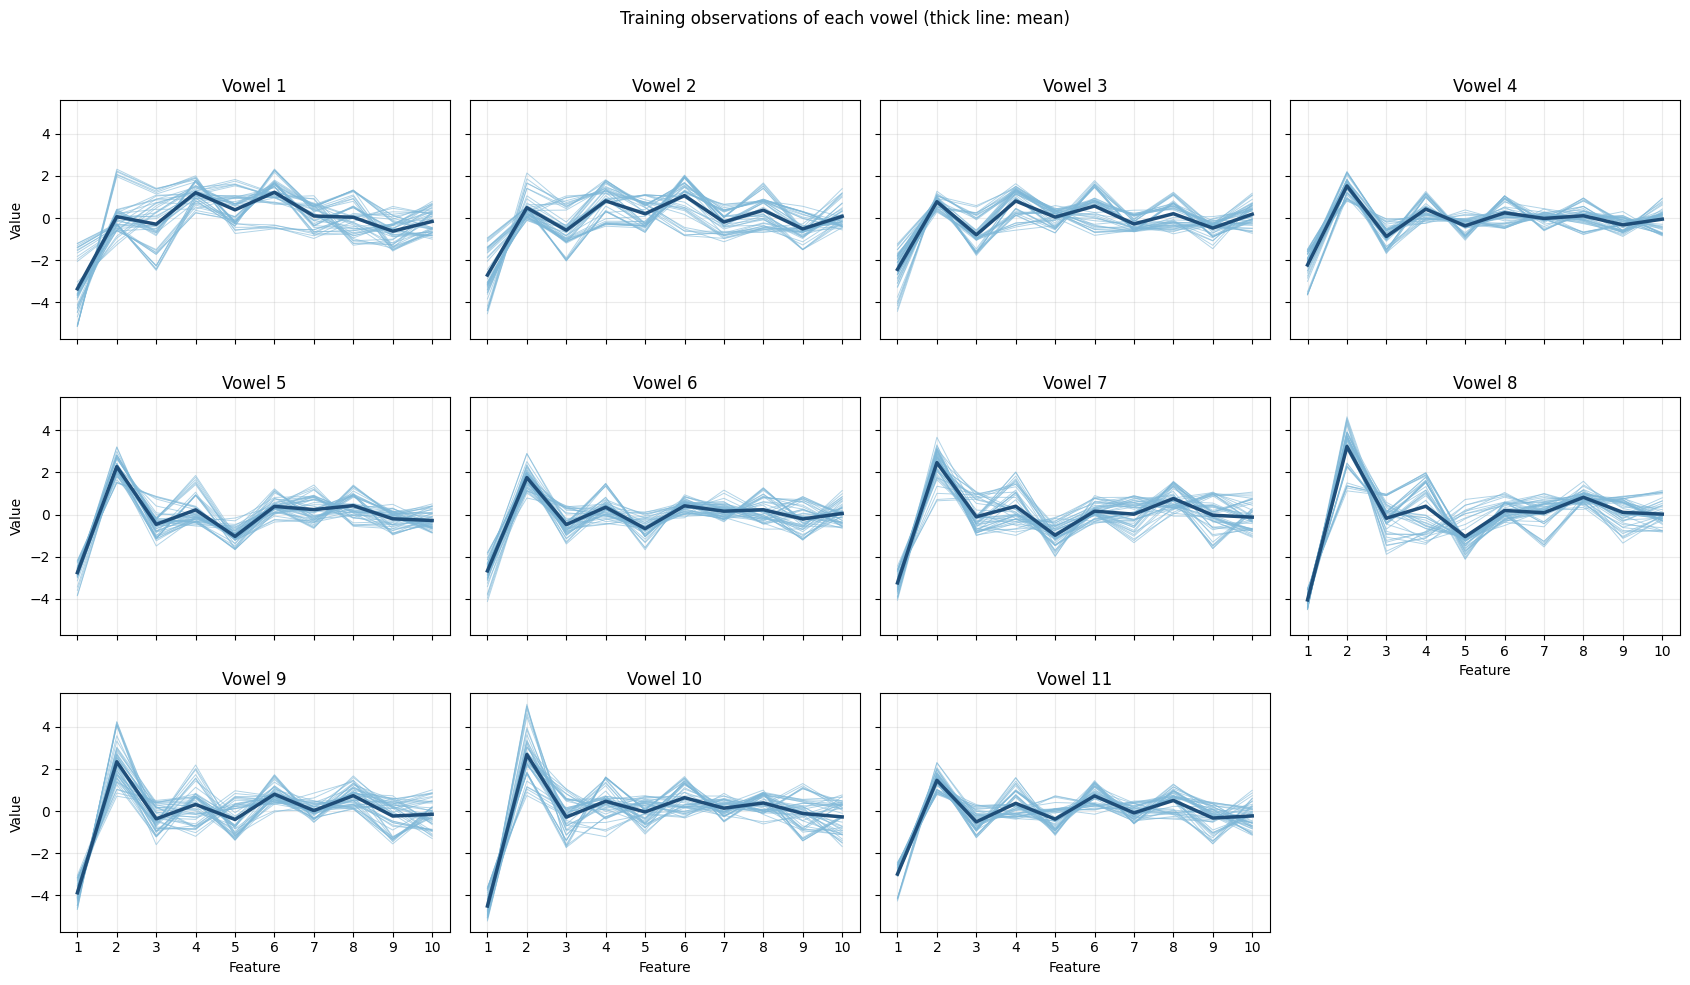

In [3]:
fig, axes = plt.subplots(3, 4, figsize=(17, 10), sharex=True, sharey=True)
for ax, k in zip(axes.ravel(), classes):
    dat_aux = dat_train.loc[dat_train['y'] == k, features]
    ax.plot(range(1, 11), dat_aux.T, color='#7fb8d8', lw=0.7, alpha=0.6)
    ax.plot(range(1, 11), dat_aux.mean(), color='#1f4e79', lw=2.5)
    ax.set_title(f'Vowel {k}')
    ax.set_xticks(range(1, 11))
    ax.grid(True, alpha=0.25)
axes.ravel()[-1].set_axis_off()
for ax in axes[-1, :3]:
    ax.set_xlabel('Feature')
axes[1, 3].set_xlabel('Feature')
axes[1, 3].tick_params(labelbottom=True)
for ax in axes[:, 0]:
    ax.set_ylabel('Value')
fig.suptitle('Training observations of each vowel (thick line: mean)')
fig.tight_layout(rect=(0, 0, 1, 0.96))

In [4]:
def errors(Y_train_hat, Y_test_hat):
    # Percentage of misclassified observations in the training and in the testing set
    error_train = (1-np.diag(confusion_matrix(dat_train['y'], Y_train_hat)).sum()/n_train)*100
    error_test = (1-np.diag(confusion_matrix(dat_test['y'], Y_test_hat)).sum()/n_test)*100
    print(f'Training error: {error_train:.0f}%')
    print(f'Testing error:  {error_test:.0f}%')
    return error_train, error_test

results = {}

## Using linear regression

We code the class with 11 indicator variables and fit a linear regression to each of them. An observation is assigned to the class with the largest fitted value.

In [5]:
Y_train = pd.get_dummies(dat_train['y'], dtype=float)
X_train = np.column_stack([np.ones(n_train), dat_train[features]])

X_test = np.column_stack([np.ones(n_test), dat_test[features]])

beta_hat = np.linalg.solve(X_train.T @ X_train, X_train.T @ Y_train.to_numpy())
linreg_train = X_train @ beta_hat
linreg_test  = X_test @ beta_hat

Y_train_hat_linreg = classes[linreg_train.argmax(axis=1)]
Y_test_hat_linreg  = classes[linreg_test.argmax(axis=1)]

results['Linear regression'] = errors(Y_train_hat_linreg, Y_test_hat_linreg)

Training error: 48%
Testing error:  67%


## Logistic regression

In [6]:
logreg = LogisticRegression(max_iter=5000)
logreg.fit(dat_train[features], dat_train['y'])

Y_train_hat_logreg = logreg.predict(dat_train[features])
Y_test_hat_logreg = logreg.predict(dat_test[features])

results['Logistic regression'] = errors(Y_train_hat_logreg, Y_test_hat_logreg)

Training error: 27%
Testing error:  52%


## Linear discriminant analysis

In [7]:
lda = LinearDiscriminantAnalysis()
lda.fit(dat_train[features], dat_train['y'])

Y_train_hat_lda = lda.predict(dat_train[features])
Y_test_hat_lda = lda.predict(dat_test[features])

results['Linear discriminant analysis'] = errors(Y_train_hat_lda, Y_test_hat_lda)

Training error: 32%
Testing error:  56%


## Quadratic discriminant analysis

In [8]:
qda = QuadraticDiscriminantAnalysis()
qda.fit(dat_train[features], dat_train['y'])

Y_train_hat_qda = qda.predict(dat_train[features])
Y_test_hat_qda = qda.predict(dat_test[features])

results['Quadratic discriminant analysis'] = errors(Y_train_hat_qda, Y_test_hat_qda)

Training error: 1%
Testing error:  53%


## Comparing the methods

The testing error is much larger than the training error for all the methods: the testing speakers are different people. QDA, with one covariance matrix for each vowel (55 parameters each), almost memorizes the training data, but with new speakers it is not better than the logistic regression or LDA.

In [9]:
table = pd.DataFrame(results, index=['Training error (%)', 'Testing error (%)']).T.sort_values('Testing error (%)')
table.round(1)

,Training error (%),Testing error (%)
Logistic regression,27.3,52.4
Quadratic discriminant analysis,1.1,52.8
Linear discriminant analysis,31.6,55.6
Linear regression,47.7,66.7


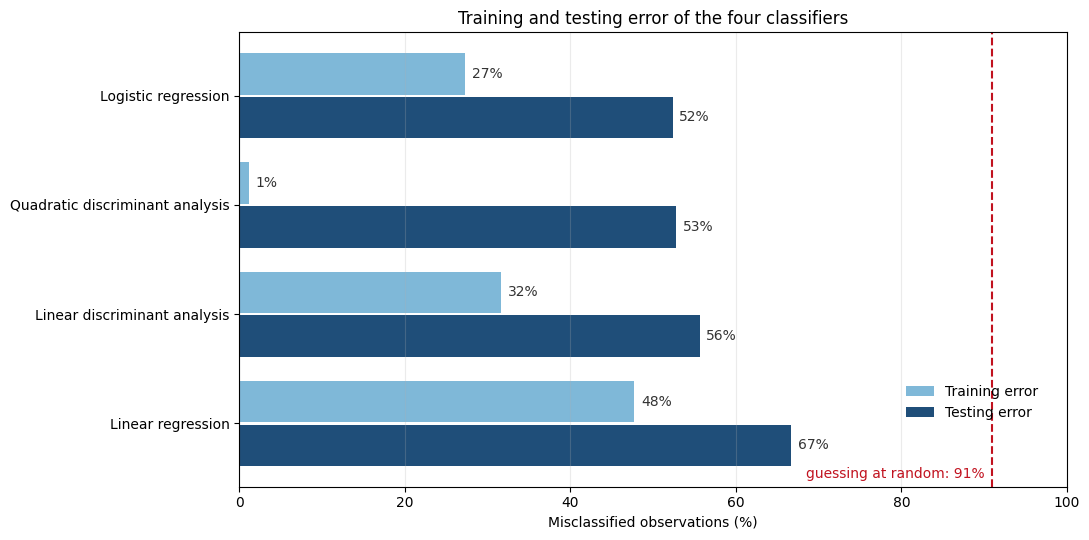

In [10]:
fig, ax = plt.subplots(figsize=(11, 5.5))
pos = np.arange(len(table))
ax.barh(pos-0.2, table['Training error (%)'], height=0.38, color='#7fb8d8', label='Training error')
ax.barh(pos+0.2, table['Testing error (%)'], height=0.38, color='#1f4e79', label='Testing error')
for i, (train, test) in enumerate(table.to_numpy()):
    ax.text(train+0.8, i-0.2, f'{train:.0f}%', va='center', fontsize=10, color='#333333')
    ax.text(test+0.8, i+0.2, f'{test:.0f}%', va='center', fontsize=10, color='#333333')
ax.axvline(100*(1-1/11), ls='--', color='#c1121f', lw=1.5)
ax.annotate('guessing at random: 91%', (100*(1-1/11), 0), xycoords=('data', 'axes fraction'), xytext=(-5, 6),
            textcoords='offset points', ha='right', fontsize=10, color='#c1121f')
ax.set_yticks(pos, table.index)
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel('Misclassified observations (%)')
ax.set_title('Training and testing error of the four classifiers')
ax.legend(loc='lower right', frameon=False, bbox_to_anchor=(0.98, 0.12))
ax.grid(True, axis='x', alpha=0.25)
plt.tight_layout()

## Confusion matrices of LDA

The rows are the actual vowels and the columns the predicted ones. In the testing set some vowels are confused systematically with another one.

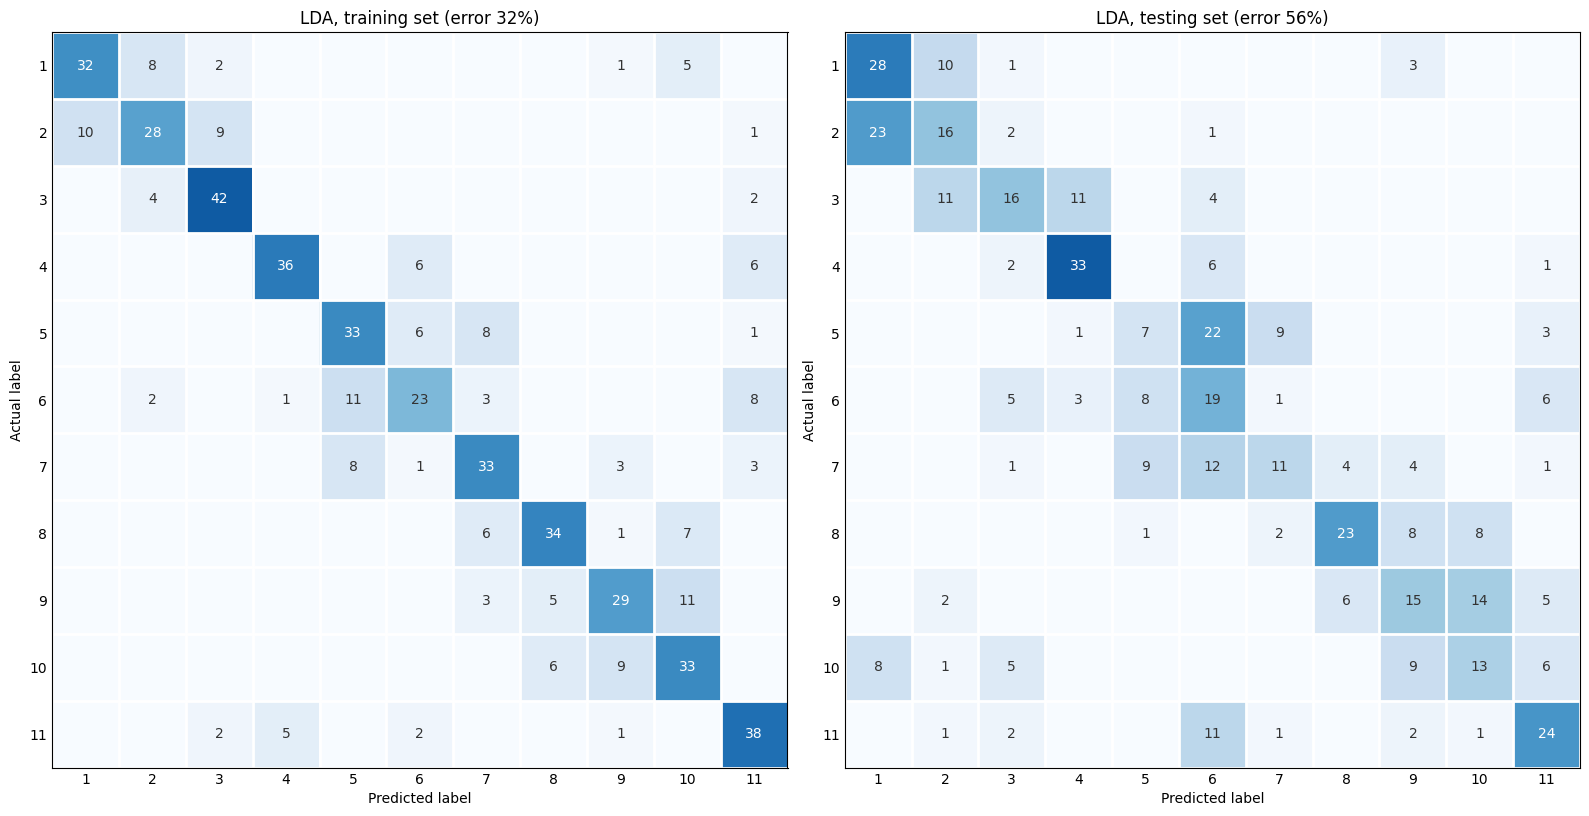

In [11]:
confusion_matrix_train_lda = confusion_matrix(dat_train['y'], Y_train_hat_lda)
confusion_matrix_test_lda  = confusion_matrix(dat_test['y'], Y_test_hat_lda)

def plot_confusion_matrix(ax, matrix, title):
    ax.imshow(matrix, cmap='Blues', vmin=0, vmax=matrix.max()*1.2)
    for i in range(len(classes)):
        for j in range(len(classes)):
            if matrix[i, j] > 0:
                ax.text(j, i, matrix[i, j], ha='center', va='center', fontsize=10,
                        color='white' if matrix[i, j] > 0.6*matrix.max() else '#333333')
    ax.set_xticks(range(len(classes)), classes)
    ax.set_yticks(range(len(classes)), classes)
    ax.set_xticks(np.arange(len(classes)+1)-0.5, minor=True)
    ax.set_yticks(np.arange(len(classes)+1)-0.5, minor=True)
    ax.grid(which='minor', color='white', linewidth=2)
    ax.tick_params(which='both', length=0)
    ax.set_xlabel('Predicted label')
    ax.set_ylabel('Actual label')
    ax.set_title(title)

fig, axes = plt.subplots(1, 2, figsize=(16, 8))
plot_confusion_matrix(axes[0], confusion_matrix_train_lda,
                      f'LDA, training set (error {results["Linear discriminant analysis"][0]:.0f}%)')
plot_confusion_matrix(axes[1], confusion_matrix_test_lda,
                      f'LDA, testing set (error {results["Linear discriminant analysis"][1]:.0f}%)')
plt.tight_layout()